# SVM Sentiment Analysis — Amazon Reviews

Analiza sentymentu recenzji Amazon za pomocą SVM z pełnym pipeline'em:
- **TF-IDF** jako reprezentacja tekstu
- **LinearSVC** jako klasyfikator
- **Podział danych**: Train / Validation / Test
- **Cross-validation** na zbiorze treningowym
- **GridSearchCV** na zbiorze train+validation
- **Finalna ewaluacja** na zbiorze testowym

## 1. Importy

In [1]:
import pandas as pd
import numpy as np
import time
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, f1_score

import seaborn as sns
import matplotlib.pyplot as plt

print("Importy załadowane pomyślnie.")

Importy załadowane pomyślnie.


## 2. Wczytanie danych

In [2]:
df = pd.read_csv('data/processed_reviews.csv')

print(f"Liczba próbek: {len(df)}")
print(f"Kolumny: {df.columns.tolist()}")
print("\nRozkład klas (label):")
print(df['label'].value_counts().sort_index())

df.head(3)

Liczba próbek: 89511
Kolumny: ['id', 'full_text', 'score', 'sentiment', 'label']

Rozkład klas (label):
label
0    29837
1    29837
2    29837
Name: count, dtype: int64


,id,full_text,score,sentiment,label
0,497575,It's not equal amounts of each flavor... Just ...,3,0,1
1,333710,Not A Gingerbread Man These do taste very good...,4,1,2
2,275773,"great taste great taste, good price... Always ...",5,1,2


## 3. Podział danych: Train / Validation / Test

Strategia podziału:
- **Test set (20%)** — odkładamy na sam koniec, dotykamy go tylko raz
- **Validation set (15% całości = ~19% pozostałych)** — służy do oceny modeli z GridSearch i wyboru najlepszego
- **Train set (65% całości)** — na nim odbywa się cross-validation i trening

```
Cały dataset
│
├── Test (20%)          ← finalna ewaluacja, dotykamy tylko raz na końcu
│
└── Reszta (80%)
    ├── Validation (15% całości ≈ 19% reszty)  ← wybór modelu po GridSearch
    └── Train (65% całości ≈ 81% reszty)        ← CV + GridSearchCV
```

In [3]:
X = df['full_text']
y = df['label']

# Krok 1: Odłóż zbiór testowy (20%)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Krok 2: Z pozostałych 80% wydziel zbiór walidacyjny (~19% z 80% = 15% całości)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.1875,  # 0.1875 * 0.80 ≈ 0.15 całości
    random_state=42,
    stratify=y_temp
)

print(f"Train:      {len(X_train):>6} próbek ({len(X_train)/len(X)*100:.1f}%)")
print(f"Validation: {len(X_val):>6} próbek ({len(X_val)/len(X)*100:.1f}%)")
print(f"Test:       {len(X_test):>6} próbek ({len(X_test)/len(X)*100:.1f}%)")
print(f"\nRozkład klas w Train:")
print(y_train.value_counts().sort_index())
print(f"\nRozkład klas w Validation:")
print(y_val.value_counts().sort_index())
print(f"\nRozkład klas w Test:")
print(y_test.value_counts().sort_index())

Train:       58181 próbek (65.0%)
Validation:  13427 próbek (15.0%)
Test:        17903 próbek (20.0%)

Rozkład klas w Train:
label
0    19394
1    19393
2    19394
Name: count, dtype: int64

Rozkład klas w Validation:
label
0    4476
1    4476
2    4475
Name: count, dtype: int64

Rozkład klas w Test:
label
0    5967
1    5968
2    5968
Name: count, dtype: int64


## 4. Baseline Pipeline

Budujemy bazowy pipeline z parametrami wynikającymi z wcześniejszych eksperymentów:
- `stop_words=None` — negacje ('not', 'no') niosą istotną informację o sentymencie
- `ngram_range=(1,3)` — trigramy pomagają łapać frazy jak 'not good at all'
- `C=1` — dobry punkt startowy dla LinearSVC

In [4]:
baseline_pipe = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=30000,
        stop_words=None,      # zachowujemy negacje
        ngram_range=(1, 3),   # uni + bi + trigramy
        lowercase=True,
        min_df=3
    )),
    ('svm', LinearSVC(
        C=1,
        max_iter=3000,
        dual='auto',
        random_state=42
    ))
])

print("Pipeline zdefiniowany:")
print(baseline_pipe)

Pipeline zdefiniowany:
Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=30000, min_df=3,
                                 ngram_range=(1, 3))),
                ('svm', LinearSVC(C=1, max_iter=3000, random_state=42))])


## 5. Cross-Validation na zbiorze treningowym

CV działa wyłącznie na `X_train` — pipeline gwarantuje brak data leakage
(TF-IDF jest fitowany osobno dla każdego foldu).

Uruchamianie 5-fold Cross-Validation na zbiorze treningowym...
Czas: 31.4s

CV F1-macro: 0.7449 ± 0.0029
Wyniki per fold: [0.7448 0.7394 0.7476 0.7466 0.746 ]


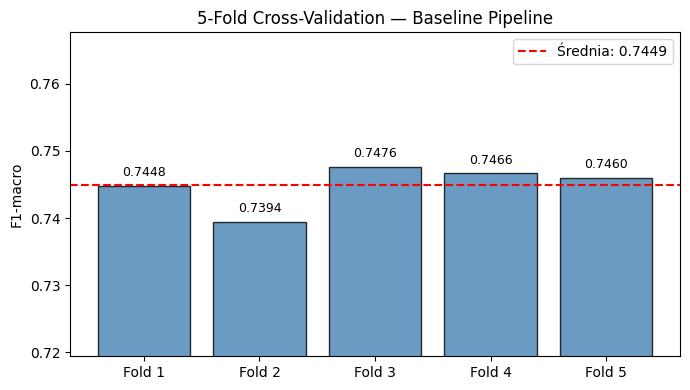

In [5]:
print("Uruchamianie 5-fold Cross-Validation na zbiorze treningowym...")
start = time.time()

cv_scores = cross_val_score(
    baseline_pipe,
    X_train, y_train,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

print(f"Czas: {time.time() - start:.1f}s")
print(f"\nCV F1-macro: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
print(f"Wyniki per fold: {np.round(cv_scores, 4)}")

# Wizualizacja wyników CV
fig, ax = plt.subplots(figsize=(7, 4))
folds = [f'Fold {i+1}' for i in range(len(cv_scores))]
bars = ax.bar(folds, cv_scores, color='steelblue', alpha=0.8, edgecolor='black')
ax.axhline(cv_scores.mean(), color='red', linestyle='--', label=f'Średnia: {cv_scores.mean():.4f}')
ax.set_ylim(max(0, cv_scores.min() - 0.02), min(1, cv_scores.max() + 0.02))
ax.set_ylabel('F1-macro')
ax.set_title('5-Fold Cross-Validation — Baseline Pipeline')
ax.legend()
for bar, score in zip(bars, cv_scores):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
            f'{score:.4f}', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

## 6. Grid Search — dobór optymalnych hiperparametrów

GridSearchCV przeszukuje siatkę parametrów używając wewnętrznej CV na `X_train`.
Siatka jest celowo ograniczona — zbyt duża powoduje kombinatoryczną eksplozję.

**Strategia**: testujemy kluczowe osie zmienności:
- `max_features` i `ngram_range` w TF-IDF
- `C` w LinearSVC (regularyzacja)
- `class_weight` (pomocne przy niezbalansowanych klasach)

In [7]:
# Pipeline dla GridSearch — osobna instancja, żeby nie modyfikować baseline
gs_pipe = Pipeline([
    ('tfidf', TfidfVectorizer(
        lowercase=True,
        stop_words=None,
    )),
    ('svm', LinearSVC(
        max_iter=3000,
        random_state=42,
        dual='auto'
    ))
])

# Siatka parametrów
# Łącznie: 3 * 2 * 2 * 2 = 24 kombinacje × 3 foldy = 72 fity
param_grid = {
    'tfidf__max_features': [15000, 30000, None],
    'tfidf__ngram_range':  [(1, 2), (1, 3)],
    'svm__C':              [0.3, 1, 5],
    'svm__class_weight':   [None, 'balanced'],
}

grid_search = GridSearchCV(
    gs_pipe,
    param_grid,
    cv=3,               # 3-fold wewnątrz GridSearch (szybciej niż 5)
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1,
    refit=True          # automatycznie refituje best model na całym X_train
)

n_combinations = (3 * 2 * 3 * 2)
print(f"Liczba kombinacji: {n_combinations} × 3 foldy = {n_combinations * 3} fitów")
print("Uruchamianie GridSearchCV...")
start = time.time()

grid_search.fit(X_train, y_train)

print(f"\nGotowe! Czas: {time.time() - start:.1f}s")
print(f"\nNajlepsze parametry:")
for k, v in grid_search.best_params_.items():
    print(f"  {k}: {v}")
print(f"\nNajlepszy CV F1-macro (train): {grid_search.best_score_:.4f}")

Liczba kombinacji: 36 × 3 foldy = 108 fitów
Uruchamianie GridSearchCV...
Fitting 3 folds for each of 36 candidates, totalling 108 fits

Gotowe! Czas: 488.0s

Najlepsze parametry:
  svm__C: 1
  svm__class_weight: None
  tfidf__max_features: None
  tfidf__ngram_range: (1, 3)

Najlepszy CV F1-macro (train): 0.7632


In [8]:
# Przegląd wyników Grid Search — top 10 kombinacji
cv_results = pd.DataFrame(grid_search.cv_results_)
top10 = (cv_results
         .sort_values('mean_test_score', ascending=False)
         .head(10)[['param_tfidf__max_features', 'param_tfidf__ngram_range',
                    'param_svm__C', 'param_svm__class_weight',
                    'mean_test_score', 'std_test_score']]
         .reset_index(drop=True))

top10.columns = ['max_features', 'ngram_range', 'C', 'class_weight',
                 'mean_F1', 'std_F1']
top10['mean_F1'] = top10['mean_F1'].round(4)
top10['std_F1']  = top10['std_F1'].round(4)

print("Top 10 kombinacji hiperparametrów:")
display(top10)

Top 10 kombinacji hiperparametrów:


,max_features,ngram_range,C,class_weight,mean_F1,std_F1
0,None,"(1, 3)",1.0,balanced,0.7632,0.0023
1,None,"(1, 3)",1.0,None,0.7632,0.0023
2,None,"(1, 3)",0.3,None,0.7616,0.0017
3,None,"(1, 3)",0.3,balanced,0.7616,0.0017
4,None,"(1, 3)",5.0,balanced,0.7612,0.0024
5,None,"(1, 3)",5.0,None,0.7612,0.0023
6,None,"(1, 2)",0.3,None,0.7606,0.0020
7,None,"(1, 2)",0.3,balanced,0.7606,0.0020
8,None,"(1, 2)",1.0,None,0.7563,0.0013
9,None,"(1, 2)",1.0,balanced,0.7563,0.0013


## 7. Ewaluacja na zbiorze walidacyjnym

Zbiór walidacyjny był **niewidoczny** podczas Grid Search.
Używamy go teraz do weryfikacji, czy najlepszy model generalizuje.

In [9]:
best_model = grid_search.best_estimator_

# Predykcja na zbiorze walidacyjnym
y_val_pred = best_model.predict(X_val)
val_f1 = f1_score(y_val, y_val_pred, average='macro')

print("=" * 55)
print("WYNIKI NA ZBIORZE WALIDACYJNYM (model z GridSearch)")
print("=" * 55)
print(f"CV F1-macro (train, wewnętrzny): {grid_search.best_score_:.4f}")
print(f"F1-macro   (validation):         {val_f1:.4f}")
print()
print(classification_report(
    y_val, y_val_pred,
    target_names=['Negative (1-2)', 'Neutral (3)', 'Positive (4-5)']
))

WYNIKI NA ZBIORZE WALIDACYJNYM (model z GridSearch)
CV F1-macro (train, wewnętrzny): 0.7632
F1-macro   (validation):         0.7743

                precision    recall  f1-score   support

Negative (1-2)       0.77      0.77      0.77      4476
   Neutral (3)       0.70      0.70      0.70      4476
Positive (4-5)       0.85      0.86      0.86      4475

      accuracy                           0.77     13427
     macro avg       0.77      0.77      0.77     13427
  weighted avg       0.77      0.77      0.77     13427



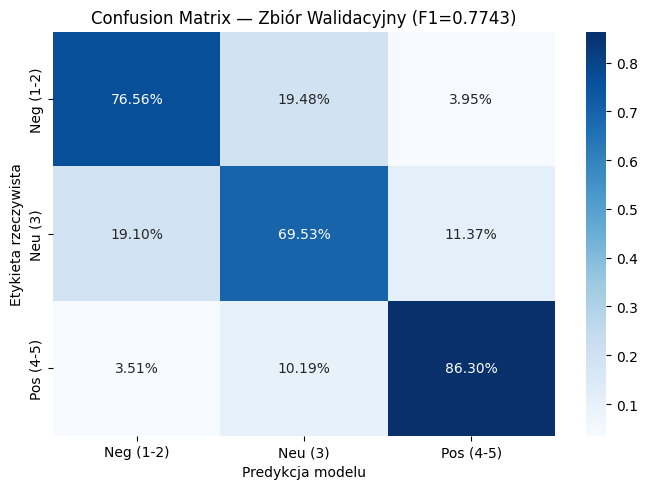

In [10]:
# Confusion matrix — zbiór walidacyjny
cm_val = confusion_matrix(y_val, y_val_pred)
cm_val_pct = cm_val.astype(float) / cm_val.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(7, 5))
sns.heatmap(cm_val_pct, annot=True, fmt='.2%', cmap='Blues',
            xticklabels=['Neg (1-2)', 'Neu (3)', 'Pos (4-5)'],
            yticklabels=['Neg (1-2)', 'Neu (3)', 'Pos (4-5)'])
plt.ylabel('Etykieta rzeczywista')
plt.xlabel('Predykcja modelu')
plt.title(f'Confusion Matrix — Zbiór Walidacyjny (F1={val_f1:.4f})')
plt.tight_layout()
plt.show()

## 8. Finalna ewaluacja na zbiorze testowym

> **Uwaga**: Ta komórka jest uruchamiana **tylko raz**, po zakończeniu wszystkich eksperymentów.
> Wyniki testowe nie mogą wpływać na dalsze decyzje modelarskie.

Przed finalnym testem refitujemy model na połączonych danych train + validation,
żeby w pełni wykorzystać wszystkie dostępne oznaczone dane.

In [ ]:
import copy
import time # Upewnij się, że masz import

# Łączymy train + validation → trenujemy final model
X_trainval = pd.concat([X_train, X_val])
y_trainval = pd.concat([y_train, y_val])

print("Rozpoczynanie finalnego treningu...")
start_train = time.time()

# Kopiujemy best pipeline i trenujemy na train+val
final_model = copy.deepcopy(best_model)
final_model.fit(X_trainval, y_trainval)

train_time_final = time.time() - start_train
print(f"Czas trenowania finalnego modelu: {train_time_final:.2f} s")

# Predykcja na zbiorze testowym
# mierzymy czas dla całego zbioru testowego, żeby wynik był miarodajny
start_predict = time.time()

y_test_pred = final_model.predict(X_test)

predict_time_total = time.time() - start_predict
predict_time_per_1k = (predict_time_total / len(X_test)) * 1000

print(f"Czas predykcji (łącznie dla {len(X_test)} próbek): {predict_time_total:.4f} s")
print(f"Czas predykcji na 1000 recenzji: {predict_time_per_1k:.4f} s")

test_f1 = f1_score(y_test, y_test_pred, average='macro')

print("=" * 55)
print("FINALNE WYNIKI NA ZBIORZE TESTOWYM")
print("=" * 55)
print(f"F1-macro (test): {test_f1:.4f}")
print(f"Czas treningu: {train_time_final:.2f} s")
print("-" * 55)
print(classification_report(
    y_test, y_test_pred,
    target_names=['Negative (1-2)', 'Neutral (3)', 'Positive (4-5)']
))

Rozpoczynanie finalnego treningu...
Czas trenowania finalnego modelu: 30.85 s
Czas predykcji (łącznie dla 17903 próbek): 2.6786 s
Czas predykcji na 1000 recenzji: 0.1496 s
FINALNE WYNIKI NA ZBIORZE TESTOWYM
F1-macro (test): 0.7769
Czas treningu: 30.85 s
-------------------------------------------------------
                precision    recall  f1-score   support

Negative (1-2)       0.79      0.77      0.78      5967
   Neutral (3)       0.70      0.70      0.70      5968
Positive (4-5)       0.85      0.87      0.86      5968

      accuracy                           0.78     17903
     macro avg       0.78      0.78      0.78     17903
  weighted avg       0.78      0.78      0.78     17903



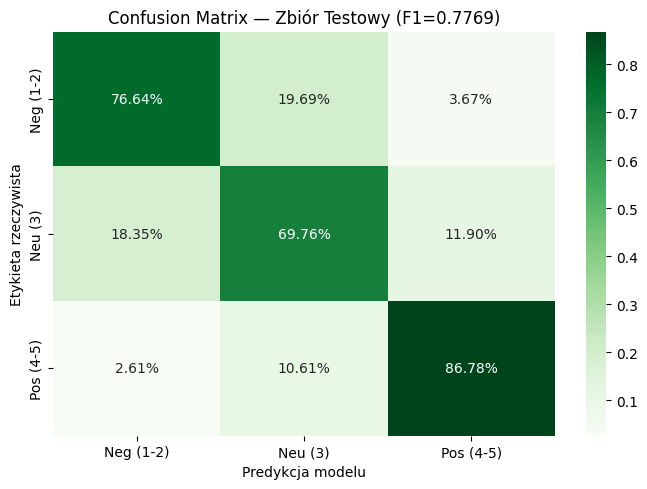

In [12]:
# Confusion matrix — zbiór testowy
cm_test = confusion_matrix(y_test, y_test_pred)
cm_test_pct = cm_test.astype(float) / cm_test.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(7, 5))
sns.heatmap(cm_test_pct, annot=True, fmt='.2%', cmap='Greens',
            xticklabels=['Neg (1-2)', 'Neu (3)', 'Pos (4-5)'],
            yticklabels=['Neg (1-2)', 'Neu (3)', 'Pos (4-5)'])
plt.ylabel('Etykieta rzeczywista')
plt.xlabel('Predykcja modelu')
plt.title(f'Confusion Matrix — Zbiór Testowy (F1={test_f1:.4f})')
plt.tight_layout()
plt.show()

## 9. Podsumowanie wyników

In [16]:
print("=" * 55)
print("PODSUMOWANIE EKSPERYMENTU")
print("=" * 55)
print(f"\nPodział danych:")
print(f"  Train:      {len(X_train):>6} próbek")
print(f"  Validation: {len(X_val):>6} próbek")
print(f"  Test:       {len(X_test):>6} próbek")

print(f"\nWyniki:")
print(f"  CV F1-macro  (train, 5-fold baseline): {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
print(f"  CV F1-macro  (train, GridSearch best): {grid_search.best_score_:.4f}")
print(f"  F1-macro     (validation):             {val_f1:.4f}")
print(f"  F1-macro     (test — FINALNA):         {test_f1:.4f}")

print(f"\nNajlepsze hiperparametry (GridSearch):")
for k, v in grid_search.best_params_.items():
    print(f"  {k}: {v}")

vectorizer = final_model.named_steps['tfidf']
n_features = len(vectorizer.get_feature_names_out())
print(f"  Ostateczna liczba atrybutów (tokenów): {n_features:,}".replace(',', ' '))

PODSUMOWANIE EKSPERYMENTU

Podział danych:
  Train:       58181 próbek
  Validation:  13427 próbek
  Test:        17903 próbek

Wyniki:
  CV F1-macro  (train, 5-fold baseline): 0.7449 ± 0.0029
  CV F1-macro  (train, GridSearch best): 0.7632
  F1-macro     (validation):             0.7743
  F1-macro     (test — FINALNA):         0.7769

Najlepsze hiperparametry (GridSearch):
  svm__C: 1
  svm__class_weight: None
  tfidf__max_features: None
  tfidf__ngram_range: (1, 3)
  Ostateczna liczba atrybutów (tokenów): 4 521 412


## 10. Analiza błędów

In [14]:
results_df = pd.DataFrame({
    'text':      X_test.values,
    'actual':    y_test.values,
    'predicted': y_test_pred
})

errors = results_df[results_df['actual'] != results_df['predicted']]
print(f"Błędnych predykcji: {len(errors)} / {len(results_df)} "
      f"({len(errors)/len(results_df)*100:.1f}%)")

# Skrajne pomyłki: Negatyw → Pozytyw
label_values = sorted(y.unique())
neg_label = label_values[0]   # najniższa klasa = negatywna
pos_label = label_values[-1]  # najwyższa klasa = pozytywna

extreme = errors[(errors['actual'] == neg_label) & (errors['predicted'] == pos_label)]
print(f"\nSkrajne pomyłki (Negatyw → Pozytyw): {len(extreme)}")

for _, row in extreme.head(5).iterrows():
    print(f"\n[actual={row['actual']} | pred={row['predicted']}]")
    print(f"  {str(row['text'])[:250]}...")

Błędnych predykcji: 3988 / 17903 (22.3%)

Skrajne pomyłki (Negatyw → Pozytyw): 219

[actual=0 | pred=2]
  Serious health food If you're out for sheer health benefits without taste and without desirable texture, this one's for you.  I did not expect much out of it except health benefits, so I wasn't surprised.  You should only try this product if you have...

[actual=0 | pred=2]
  My cat hates this stuff... I had to but my cat friskee pate canned cat food instead of this canned stuff. My cat lost weight cause she wouldnt eat it. I had 2 different cases from amazon and also different flavors of filet that i had brought from the...

[actual=0 | pred=2]
  I was hoping to love this coffee, but it is very bitter. I have been searching for a smooth, flavorful decaf K cup that I could actually enjoy. I was thrilled to find  Folgers Gourmet Lively Columbian medium roast decaf K cup to try, but both my husb...

[actual=0 | pred=2]
  frenchs horseradish mustard first of all I like Frenchs regular